## Student Performance Analysis — EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:

df = pd.read_csv(r"D:\archive\StudentsPerformance.csv")


In [6]:
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


## Dataset Overview

In [7]:
df.info()
display(df.describe(include="all").T)
print("Columns:", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race/ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental level of education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test preparation course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


Columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


## Data Quality

In [9]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage":(df.isna().mean() * 100).round(2)
})

display(missing)
print("Duplicate rows:", df.duplicated().sum())

df_clean = df.drop_duplicates().copy()
print("Before:", df.shape,"|After:", df_clean.shape)

,Missing Count,Missing Percentage
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Duplicate rows: 0
Before: (1000, 8) |After: (1000, 8)


## Score Summary and Distributions

,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


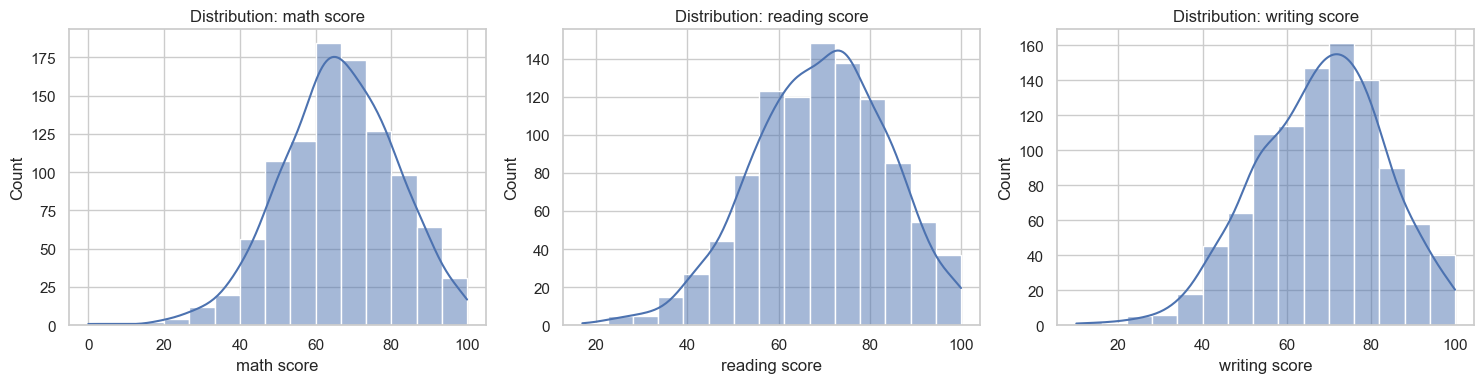

In [10]:
score_cols = ["math score", "reading score", "writing score"]
display(df_clean[score_cols].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, score_cols):
    sns.histplot(data=df_clean, x=col, bins=15, kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()


## Average Scores by Gender

,math score,reading score,writing score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


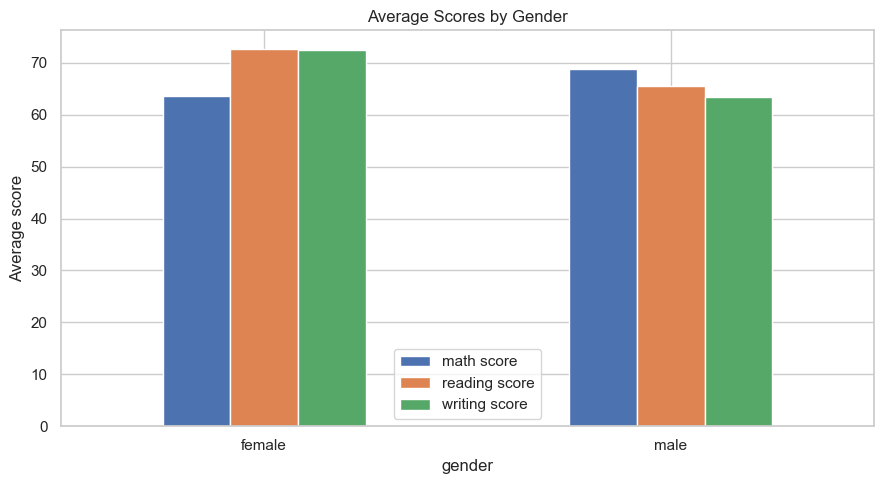

In [11]:
gender_avg = df_clean.groupby("gender")[score_cols].mean().round(2)
display(gender_avg)
gender_avg.plot(kind="bar", figsize=(9, 5))
plt.title("Average Scores by Gender")
plt.ylabel("Average score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Test Preparation

,math score,reading score,writing score
test preparation course,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


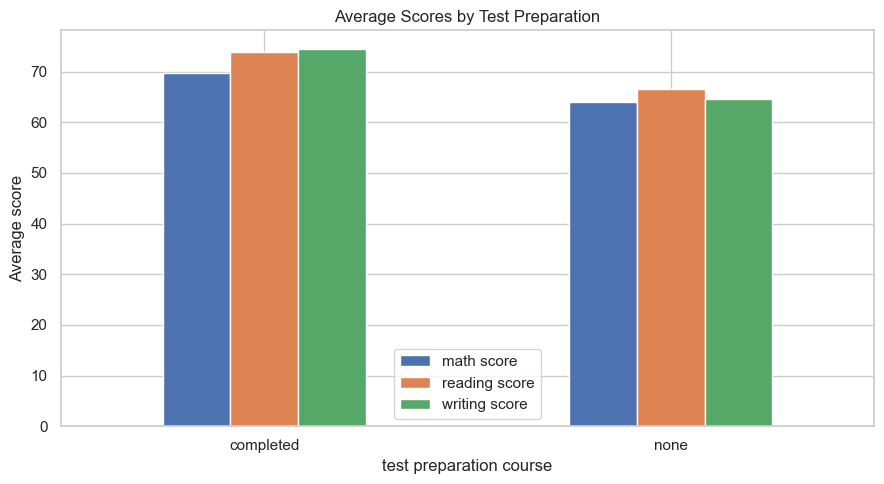

In [13]:
prep_avg = df_clean.groupby("test preparation course")[score_cols].mean().round(2)
display(prep_avg)
prep_avg.plot(kind="bar", figsize=(9, 5))
plt.title("Average Scores by Test Preparation")
plt.ylabel("Average score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Correlation Between Subjects

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


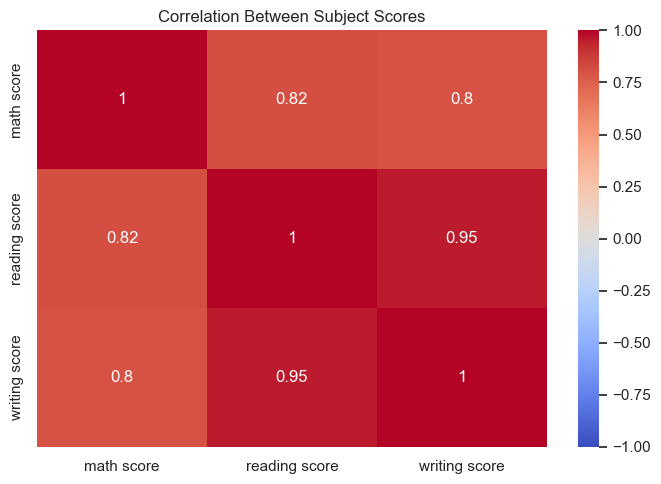

In [14]:
corr = df_clean[score_cols].corr()
display(corr)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Subject Scores")
plt.tight_layout()
plt.show()


##  Key Insights and Conclusion
- Which subject has the highest average score?
- Which group has higher averages in each subject?
- How do test-preparation averages compare?
- Which subjects are most strongly correlated?